# Linear algebra 9: Linear differential equations, the matrix exponential and the Jordan form

*Learning path: linear algebra, part 9 of 9.* [Index](README.md) · Previous: [The singular value decomposition](08-svd.ipynb)

A drug spreads from the blood into tissue and back. Two tanks of brine are connected by pipes. A car's suspension
bounces after a bump. Each is a system of linear differential equations $x' = Ax$, and each is solved by one formula,
$x(t) = e^{At}x(0)$, where $e^{At}$ is the exponential of a *matrix*. Computing it is where eigenvalues pay off, and
where the matrices that cannot be diagonalized finally get their own normal form: the **Jordan form**.

**Who this is for.** You know eigenvalues and diagonalization ([lesson 6](06-eigenvalues.ipynb)) and the derivative of
$e^{at}$. Complex numbers appear in section 3. No course on differential equations is needed.

**What you will be able to do afterwards:**

1. solve $x' = Ax$ with eigenvectors, and with the matrix exponential $e^{At}$;
2. read off from the eigenvalues whether solutions decay, grow or oscillate, and draw the phase portrait;
3. explain the factor $t\,e^{\lambda t}$ for a repeated eigenvalue with too few eigenvectors;
4. find the Jordan form $A = PJP^{-1}$ of a small matrix and say what its blocks mean.

Plan about an hour and a half.

## 1. Two tanks: solving $x' = Ax$ with eigenvectors

Two connected tanks hold amounts $x_1(t)$ and $x_2(t)$ of salt. Each loses salt to the other at rate 1 and to the drain
at rate 1:

$$x_1' = -2x_1 + x_2, \qquad x_2' = x_1 - 2x_2, \qquad\text{that is}\qquad x' = Ax,\quad A = \begin{pmatrix}-2 & 1\\ 1 & -2\end{pmatrix}.$$

One equation $x' = ax$ has the solution $e^{at}x(0)$. For a system, look for solutions of the same shape,
$x(t) = e^{\lambda t}v$: then $x' = \lambda e^{\lambda t}v$ must equal $Ax = e^{\lambda t}Av$, so $Av = \lambda v$.
**Eigenvectors give exponential solutions**, and since the equation is linear, any combination of them is a solution:

$$x(t) = c_1e^{\lambda_1t}v_1 + c_2e^{\lambda_2t}v_2.$$

In [1]:
A = [-2 1; 1 -2];
[V, D] = eig(A)

V = [1, -1;
 1,  1]
D = [-1,  0;
  0, -3]

$\lambda = -1$ with $v = [1\ 1]$ (both tanks equal: they only drain, slowly) and $\lambda = -3$ with $v = [-1\ 1]$
(a difference between the tanks evens out, fast). Starting with all salt in tank 1, $x(0) = [1\ 0] =
\tfrac12[1\ 1] - \tfrac12[-1\ 1]$, so

$$x(t) = \tfrac12e^{-t}[1\ 1] - \tfrac12e^{-3t}[-1\ 1].$$

**Try this.** Write $x_2(t)$ from that formula. Why does it start at 0, rise and then decay?

## 2. The matrix exponential

For numbers, $e^{at} = 1 + at + (at)^2/2! + \cdots$. Use the same series for a square matrix:

$$e^{At} = I + At + \frac{(At)^2}{2!} + \frac{(At)^3}{3!} + \cdots.$$

Differentiating term by term gives $\frac{d}{dt}e^{At} = Ae^{At}$, and $e^{A\cdot0} = I$. So
$x(t) = e^{At}x(0)$ solves $x' = Ax$ for **every** starting vector at once. `expm(A, t)` computes it:

In [2]:
E = expm(A, t)
simplify(E*[1; 0])
simplify(deriv(E, t) - A*E)

[(exp(-t)+exp(-3*t))/2, exp(-t)/2-exp(-3*t)/2;
 exp(-t)/2-exp(-3*t)/2, (exp(-t)+exp(-3*t))/2]

> e^(At) = I + At + (At)²/2! + … is computed from the Jordan form A = P*J*P⁻¹: e^(At) = P*e^(Jt)*P⁻¹. Each eigenvalue λ contributes e^(λt), times powers of t for a Jordan block bigger than 1×1; a complex pair a ± bi contributes e^(at)*cos(bt) and e^(at)*sin(bt). x(t) = expm(A, t)*x0 solves x' = A x with x(0) = x0.

[exp(-3*t)*(exp(2*t)+1)/2;
 exp(-3*t)*(exp(2*t)-1)/2]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[0, 0;
 0, 0]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The first column is the solution of section 1. How does Galileo compute $e^{At}$? From the diagonalization
$A = VDV^{-1}$: then $A^k = VD^kV^{-1}$, so the whole series becomes $e^{At} = Ve^{Dt}V^{-1}$, and the exponential of a
diagonal matrix just exponentiates the diagonal. One warning: $e^{A}e^{B} = e^{A + B}$ only when $AB = BA$.

The plot shows both tanks over time (time across, amount of salt up):

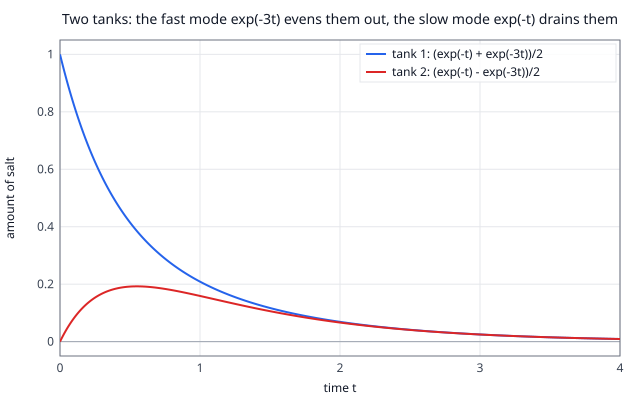

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
x = E*[1; 0];
p = plot(x(1), x(2), t, 0, 4);
p = legend(p, "tank 1: (exp(-t) + exp(-3t))/2", "tank 2: (exp(-t) - exp(-3t))/2");
labels(title(p, "Two tanks: the fast mode exp(-3t) evens them out, the slow mode exp(-t) drains them"), "time t", "amount of salt")

**Try this.** Compute `expm([2 0; 0 3], t)` in your head, then check. And `expm([0 1; 0 0], t)`: the series stops after
two terms. Why?

## 3. Oscillation, decay and the phase portrait

A car's suspension: position $y$, velocity $v = y'$, spring and damper give $y'' = -2y - 2y'$. As a first-order system
in $x = [y\ v]$:

In [4]:
B = [0 1; -2 -2];
eig(B)
expm(B, t)

[-1-i, -1+i]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

[exp(-t)*(sin(t)+cos(t)),          exp(-t)*sin(t);
       -2*exp(-t)*sin(t), exp(-t)*(cos(t)-sin(t))]

> e^(At) = I + At + (At)²/2! + … is computed from the Jordan form A = P*J*P⁻¹: e^(At) = P*e^(Jt)*P⁻¹. Each eigenvalue λ contributes e^(λt), times powers of t for a Jordan block bigger than 1×1; a complex pair a ± bi contributes e^(at)*cos(bt) and e^(at)*sin(bt). x(t) = expm(A, t)*x0 solves x' = A x with x(0) = x0.

Complex eigenvalues $-1 \pm i$ give $e^{-t}\cos t$ and $e^{-t}\sin t$: the real part $-1$ is the decay rate, the
imaginary part $1$ the frequency. (Galileo writes the result with real sines and cosines, using
$e^{(a + bi)t} = e^{at}(\cos bt + i\sin bt)$.)

The **phase portrait** draws the plane of states $[y\ v]$ with the arrows $Bx$ (where the state moves) and two
solution curves, which spiral into the origin. Axes: the position $y$ across and the velocity $v$ up.

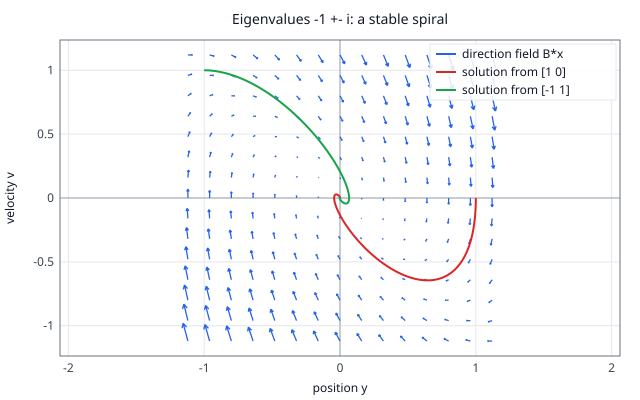

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
x1 = expm(B, t)*[1; 0];
x2 = expm(B, t)*[-1; 1];
p = show(fieldplot([y2, -2*y1 - 2*y2], y1, -1.2, 1.2, y2, -1.2, 1.2), parametric(x1(1), x1(2), t, 0, 8), parametric(x2(1), x2(2), t, 0, 8));
p = legend(p, "direction field B*x", "solution from [1 0]", "solution from [-1 1]");
labels(title(p, "Eigenvalues -1 +- i: a stable spiral"), "position y", "velocity v")

In general, for $x' = Ax$:

* all eigenvalues with **negative real part**: every solution decays to 0 (**stable**);
* some eigenvalue with **positive real part**: most solutions blow up (**unstable**);
* **imaginary parts**: rotation, so spirals or, with real part 0, closed orbits.

**Try this.** Without computing, describe the solutions of $x' = [0\ 1;\ {-4}\ 0]x$. (Eigenvalues?)

## 4. A repeated eigenvalue: where $t\,e^{\lambda t}$ comes from

Stiffen the damper a little: $y'' = -y - 2y'$, the matrix $C = [0\ 1;\ {-1}\ {-2}]$. Its characteristic polynomial is
$(\lambda + 1)^2$: the eigenvalue $-1$ twice, but only one eigenvector.

In [6]:
C = [0 1; -1 -2];
eig(C)
eigvec(C)

-1

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

[-1;
  1]

> `eigvec`: Eigenvectors, one per column, for exact eigenvalues.

No second eigenvector, so $C$ cannot be diagonalized, and the solutions are not all of the form $e^{\lambda t}v$. The
exponential still exists, and contains a new kind of term, $t\,e^{-t}$:

In [7]:
expm(C, t)

[exp(-t)*(t+1),     exp(-t)*t;
    -exp(-t)*t, exp(-t)*(1-t)]

> e^(At) = I + At + (At)²/2! + … is computed from the Jordan form A = P*J*P⁻¹: e^(At) = P*e^(Jt)*P⁻¹. Each eigenvalue λ contributes e^(λt), times powers of t for a Jordan block bigger than 1×1; a complex pair a ± bi contributes e^(at)*cos(bt) and e^(at)*sin(bt). x(t) = expm(A, t)*x0 solves x' = A x with x(0) = x0.

This is **critical damping**: the fastest return to rest without overshooting, which is what a good car suspension
aims for. Where does the $t$ come from? Write $C = -I + N$ with $N = C + I$. Then $N^2 = 0$ and $-I$ commutes with $N$,
so $e^{Ct} = e^{-t}e^{Nt} = e^{-t}(I + Nt)$: the series for $e^{Nt}$ stops after two terms.

In [8]:
N = C + eye(2);
simplify(N^2)

[0, 0;
 0, 0]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

**Try this.** Check that $y = t\,e^{-t}$ solves $y'' = -y - 2y'$ by differentiating it by hand.

## 5. The Jordan form

Every square matrix is similar to a **Jordan form** $J = P^{-1}AP$: block diagonal, each block having one eigenvalue on
its diagonal and 1s just above it,

$$J_k(\lambda) = \begin{pmatrix}\lambda & 1 & & \\ & \lambda & \ddots & \\ & & \ddots & 1\\ & & & \lambda\end{pmatrix}.$$

A $1\times1$ block is an ordinary eigenvector. A $k\times k$ block means only one eigenvector for $k$ repeats of
$\lambda$, plus a **chain** of generalized eigenvectors with $(A - \lambda I)v_j = v_{j-1}$. All blocks $1\times1$:
diagonalizable. For $C$:

In [9]:
[P, J] = jordan(C)
simplify(P*J*inv(P))

P = [ 1, 1;
 -1, 0]
J = [-1,  1;
  0, -1]

> A = P*J*P⁻¹ with J block diagonal; blocks: 2×2 for λ = -1. A block of size k means only one eigenvector for k repeats of λ; the other columns of P are generalized eigenvectors, with (A − λI)v_j = v_(j−1). A is not diagonalizable.

[ 0,  1;
 -1, -2]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

A bigger example, with eigenvalues 1, 2 and 4, where 4 appears twice but has only one eigenvector:

In [10]:
A4 = [5 4 2 1; 0 1 -1 -1; -1 -1 3 0; 1 1 -1 2];
[P, J] = jordan(A4)

P = [-1,  1,  1, 1;
  1, -1,  0, 0;
  0,  0, -1, 0;
  0,  1,  1, 0]
J = [1, 0, 0, 0;
 0, 2, 0, 0;
 0, 0, 4, 1;
 0, 0, 0, 4]

> A = P*J*P⁻¹ with J block diagonal; blocks: 1×1 for λ = 1, 1×1 for λ = 2, 2×2 for λ = 4. A block of size k means only one eigenvector for k repeats of λ; the other columns of P are generalized eigenvectors, with (A − λI)v_j = v_(j−1). A is not diagonalizable.

Column 3 of $P$ is the eigenvector for 4, and column 4 the generalized eigenvector:

In [11]:
simplify((A4 - 4*eye(4))*column(P, 3))
simplify((A4 - 4*eye(4))*column(P, 4))

[0;
 0;
 0;
 0]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

[ 1;
  0;
 -1;
  1]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

$A - 4I$ sends column 3 to 0 and column 4 to column 3: a chain of length 2, one $2\times2$ block. The exponential of a Jordan block has $e^{\lambda t}$, $t\,e^{\lambda t}$, $t^2e^{\lambda t}/2, \ldots$ above the
diagonal, which is how `expm` handles every matrix:

In [12]:
expm([2 1 0; 0 2 1; 0 0 2], t)

[exp(2*t), exp(2*t)*t, exp(2*t)*t^2/2;
        0,   exp(2*t),     exp(2*t)*t;
        0,          0,       exp(2*t)]

> e^(At) = I + At + (At)²/2! + … is computed from the Jordan form A = P*J*P⁻¹: e^(At) = P*e^(Jt)*P⁻¹. Each eigenvalue λ contributes e^(λt), times powers of t for a Jordan block bigger than 1×1; a complex pair a ± bi contributes e^(at)*cos(bt) and e^(at)*sin(bt). x(t) = expm(A, t)*x0 solves x' = A x with x(0) = x0.

A word of warning: the Jordan form is a theoretical tool. A tiny change of the entries (rounding!) splits a repeated
eigenvalue and makes the matrix diagonalizable, so numerical software avoids it and uses the Schur form or the SVD
instead. Galileo computes it exactly, from exact eigenvalues.

**Try this.** What is the Jordan form of $[3\ 1;\ 0\ 3]$? Of $[3\ 0;\ 0\ 3]$? Which one is diagonalizable?

## Exercises

1. **Diagonalizable system.** Solve $x' = [1\ 2;\ 2\ 1]x$ with $x(0) = [1\ 0]$ using eigenvectors, then check with
   `expm`. Is the origin stable?
2. **Oscillator.** For $y'' = -4y$, write the system, find $e^{At}$ and the solution with $y(0) = 1$, $y'(0) = 0$.
3. **Stability.** For which $k$ are all solutions of $x' = [-1\ k;\ 1\ {-1}]x$ decaying? (Trace and determinant.)
4. **Jordan.** Find the Jordan form of $[2\ 1\ 0;\ 0\ 2\ 0;\ 0\ 0\ 2]$. How many blocks, and why?
5. **A warning.** Show that $e^{A}e^{B} \ne e^{A + B}$ for $A = [0\ 1;\ 0\ 0]$, $B = [0\ 0;\ 1\ 0]$. (Compute all three
   with `expm`.)

## Hints and answers

* **Section 1, Try this.** $x_2 = \tfrac12(e^{-t} - e^{-3t})$: 0 at $t = 0$, rises while salt flows in from tank 1, then
  both drain.
* **Section 2, Try this.** $[e^{2t}\ 0;\ 0\ e^{3t}]$. $N = [0\ 1;\ 0\ 0]$ has $N^2 = 0$: $e^{Nt} = I + Nt = [1\ t;\ 0\ 1]$.
* **Section 3, Try this.** Eigenvalues $\pm2i$: closed orbits (ellipses), oscillation with frequency 2 forever.
* **Section 4, Try this.** $y' = (1 - t)e^{-t}$, $y'' = (t - 2)e^{-t}$, and $-y - 2y' = (-t - 2 + 2t)e^{-t}$. Equal.
* **Section 5, Try this.** $[3\ 1;\ 0\ 3]$ is already a Jordan block (not diagonalizable); $[3\ 0;\ 0\ 3]$ is two
  $1\times1$ blocks (diagonal).
* **Exercise 1.** Eigenvalues 3 ($[1\ 1]$) and $-1$ ($[-1\ 1]$): $x = \tfrac12e^{3t}[1\ 1] + \tfrac12e^{-t}[1\ {-1}]$.
  Unstable (eigenvalue 3).
* **Exercise 2.** $A = [0\ 1;\ {-4}\ 0]$, `expm([0 1; -4 0], t)` $= [\cos 2t,\ \sin(2t)/2;\ -2\sin 2t,\ \cos 2t]$;
  $y = \cos 2t$.
* **Exercise 3.** Trace $-2 < 0$; determinant $1 - k > 0$: decaying for $k < 1$.
* **Exercise 4.** One $2\times2$ block and one $1\times1$ block for $\lambda = 2$: $A - 2I$ has rank 1, so two
  eigenvectors for three repeats.
* **Exercise 5.** $e^Ae^B = [1\ 1;\ 0\ 1][1\ 0;\ 1\ 1] = [2\ 1;\ 1\ 1]$, while $e^{A+B}$ has $\cosh 1$ and $\sinh 1$
  entries. $AB \ne BA$.

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 6th ed., Wellesley-Cambridge Press (2023), sections 6.3 and 8.3.
2. M. W. Hirsch, S. Smale and R. L. Devaney, *Differential Equations, Dynamical Systems, and an Introduction to Chaos*,
   3rd ed., Academic Press (2013), chapters 3 to 6.
3. C. Moler and C. Van Loan, "Nineteen dubious ways to compute the exponential of a matrix, twenty-five years later",
   *SIAM Review* 45 (2003) 3–49.
4. C. Jordan, *Traité des substitutions et des équations algébriques*, Gauthier-Villars (1870).